In [6]:
from model import VAE_Encoder_MNIST,Ganerator_MNIST, LabelCondLatentDenoiserDeep
import torch
from torchvision import datasets, transforms
from torchvision.utils import save_image
import numpy as np
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
from com_utils import array_to_bits, bits_to_array,dequantization
from scipy.io import savemat
import os
from scipy.io import loadmat

In [7]:
device = "cuda"

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = datasets.MNIST(
    root="D:/Python/SemCom/saved_data",
    train=True,
    download=False,
    transform=transform
)

# dataloader
dl = torch.utils.data.DataLoader(dataset, batch_size=64, shuffle=False)

In [8]:
z_dim = 64
G = Ganerator_MNIST(z_dim=z_dim).to(device)
G.load_state_dict(torch.load("./save_model/G_wgangp_C.pth"))
G.eval()
for p in G.parameters():
    p.requires_grad = False

z_dim = 64
E_m = VAE_Encoder_MNIST(latent_dim=z_dim).to(device)
E_m.load_state_dict(torch.load("./save_model/E_invert_to_G_C_only.pth"))
E_m.eval()
for p in E_m.parameters():
    p.requires_grad = False

E_f = VAE_Encoder_MNIST(latent_dim=z_dim).to(device)
E_f.load_state_dict(torch.load("./save_model/E_invert_to_G_F.pth"))
E_f.eval()
for p in E_f.parameters():
    p.requires_grad = False

y_dim = 64
DM = LabelCondLatentDenoiserDeep(num_classes=2, z_dim=z_dim, tdim=128, ydim=y_dim,hidden_dim=512,num_blocks=6).to(device)
DM.load_state_dict(torch.load("./save_model/DM_latent_label_with_Channel_3.pth"))
DM.eval()
for p in DM.parameters():
    p.requires_grad = False

In [12]:
T = 1000
T_train = int(0.4 * T)
t = torch.randint(0, T_train, (B,), device=device, dtype=torch.long)

In [13]:
bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

In [16]:
bits = 8
num = 0
ber_sum = 0
error_num = 0
F = 0
M = 0
start_idx = 4
end_idx = 49
match_list = []
B = 16
# tx_data = loadmat(f'D:/matlab/result_20260317/latent_bits_M/bits_8/sample_000.mat')
for i in range(start_idx, end_idx):
    print("i= ",i)
    rx_data = loadmat(f'D:/matlab/result20260602/result/sn_{i:03d}.mat')
    rx_bits = rx_data['bits'].flatten().astype(np.uint8)

    print(rx_bits[:16])
    print(rx_bits[32:48])
    print("---------------")
    print(rx_bits[16:32])
    print(rx_bits[48:64])
    

    data = rx_bits[64:]
    print(data.shape)
    array = bits_to_array(data, bit_width=bits)
    z_deq = dequantization (array,bits)
    if isinstance(z_deq, np.ndarray):
        z_deq = torch.from_numpy(z_deq).float().to(device)
    else:
        z_deq = z_deq.float().to(device)

    z_deq = z_deq.reshape(B, z_dim)
    with torch.no_grad():
        y_m = torch.zeros(B, device=device, dtype=torch.long)
        y_f = torch.ones(B, device=device, dtype=torch.long)

        z_hat_m = DM(z_deq, t, y_m)
        z_hat_f = DM(z_deq, t, y_f)

        img_rx = G(z_deq.view(B, z_dim, 1, 1))
        img_m = G(z_hat_m.view(B, z_dim, 1, 1))
        img_f = G(z_hat_f.view(B, z_dim, 1, 1))

    save_image((img_rx + 1) / 2, f"./save_data/SDR_test/test_rx_{i:03d}.png", nrow=8)
    save_image((img_m + 1) / 2, f"./save_data/SDR_test/test_dm_mnist_{i:03d}.png", nrow=8)
    save_image((img_f + 1) / 2, f"./save_data/SDR_test/test_dm_fashion_{i:03d}.png", nrow=8)
    print("--------------------------------------")
    


print(match_list)

i=  4
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
---------------
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
(8192,)
--------------------------------------
i=  5
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
---------------
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
(8192,)
--------------------------------------
i=  6
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
---------------
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
[0 0 0 0 0 1 0 1 0 0 0 0 0 0 0 0]
(8192,)
--------------------------------------
i=  7
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
---------------
[0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0]
[0 0 0 0 0 1 0 1 0 0 1 0 0 0 0 0]
(8192,)
--------------------------------------
i=  8
[1 0 1 1 1 1 0 1 1 1 0 0 1 1 1 0]
[0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 1]
---------------
[1 1 1 1 0 1 1 0 0 0 1 0 0 0 1 0]
[0 0 1 0 0 1 0 0 0 0 0 1 0 0 1 0]
(8192,)
--------------

In [ ]:
bits = 8
qmax = 2**(bits-1) - 1
qmin = -2**(bits-1)

array = bits_to_array(rx_bits[32:], bit_width=bits)
z_deq = dequantization (array,bits)

_rec_uni = z_rec_uni.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    z_rec_llo = z_rec_llo.view(fixed_z.size(0), fixed_z.size(1), 1, 1)
    with torch.no_grad():
        z_gen_uni = G(z_rec_uni)
        z_gen_llo = G(z_rec_llo)

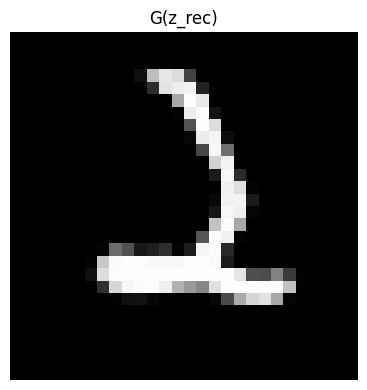